## Finding 2: Negative ratings and inspection results

**Question:** Do restaurants that fail a food inspection have a higher share of negative Google ratings beforehand?

In the EDA restaurants that failed averaged 12.5% one or two star Google ratings in the year before inspection vs 10.6% for those that passed. Here I reestimated that gap using each restaurant’s first matched inspection then check whether it holds when we change the review window, require more reviews, and so on.

**Data used:** Google restaurant info and reviews & Chicago food inspections from 2018-2021

In [105]:
import difflib
import gzip
import io
import json
import re
import time
import unicodedata
import urllib.parse
import urllib.request
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")

data_dir = next(
    (folder / "data" for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "data" / "meta-Illinois.json.gz").exists()),
    None,
)
repo_root = data_dir.resolve().parent
visualizations_dir = repo_root / "visualizations"
results_dir = repo_root / "results"
visualizations_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

RESULT_ORDER = ["Pass", "Pass w/ Conditions", "Fail"]
N_BOOT = 5000  
SEED = 418     
print("Data folder:", data_dir.resolve())

Data folder: /Users/brianarendon/Documents/CS418 Project/CS418_Economic_Trajectories_Group/data


### Data

Setup same as we used in EDA for Chicago restuarant and inspection data

In [106]:
google_metadata = pd.read_json(data_dir / "meta-Illinois.json.gz", lines=True, compression="gzip")

def has_restaurant_category(categories):
    return isinstance(categories, list) and any(
        "restaurant" in str(category).lower() for category in categories
    )

is_restaurant = google_metadata["category"].apply(has_restaurant_category)
is_chicago = google_metadata["address"].str.contains(
    r",\s*Chicago,\s*IL\b", case=False, na=False, regex=True
)
chicago_restaurants = google_metadata.loc[is_restaurant & is_chicago].copy()
chicago_restaurants = chicago_restaurants.drop_duplicates(subset="gmap_id", keep="first").copy()
print(f"Unique Chicago restaurants on Google: {len(chicago_restaurants):,}")  

Unique Chicago restaurants on Google: 8,034


### Chicago food inspections (2018-2021)

In [107]:
inspection_cache = data_dir / "food_inspections_2018_2021.csv"

if inspection_cache.exists():
    food_inspections_historical = pd.read_csv(inspection_cache)
# for future use incase could just download from Chicago data portal
else: 
    inspection_endpoint = "https://data.cityofchicago.org/resource/4ijn-s7e5.csv"
    dollar = chr(36)
    inspection_parameters = {
        dollar + "select": (
            "inspection_id,dba_name,address,inspection_date,results,latitude,longitude,"
            "risk,inspection_type"
        ),
        dollar + "where": (
            "inspection_date between '2018-01-01T00:00:00' and '2021-12-31T23:59:59' "
            "AND facility_type='Restaurant' "
            "AND results in('Pass','Pass w/ Conditions','Fail')"
        ),
        dollar + "order": "inspection_date ASC, inspection_id ASC",
        dollar + "limit": "50000",
    }
    inspection_url = inspection_endpoint + "?" + urllib.parse.urlencode(inspection_parameters)
    for attempt in range(3):
        try:
            with urllib.request.urlopen(inspection_url, timeout=120) as response:
                food_inspections_historical = pd.read_csv(io.BytesIO(response.read()))
            break
        except Exception:
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)
    if len(food_inspections_historical) >= 50000:
        raise RuntimeError("The inspection query reached its 50,000-row limit; pagination is required.")
    food_inspections_historical.to_csv(inspection_cache, index=False)

food_inspections_historical["inspection_date"] = pd.to_datetime(
    food_inspections_historical["inspection_date"], errors="coerce"
)
food_inspections_historical = food_inspections_historical.dropna(
    subset=["inspection_date", "latitude", "longitude", "dba_name"]
).copy()
food_inspections_historical = food_inspections_historical.loc[
    food_inspections_historical["latitude"].between(41.60, 42.10)
    & food_inspections_historical["longitude"].between(-87.95, -87.50)
].reset_index(drop=True)

print(f"Restaurant inspections: {len(food_inspections_historical):,}")        
display(food_inspections_historical["results"].value_counts())

Restaurant inspections: 38,360


results
Pass                  15351
Pass w/ Conditions    14563
Fail                   8446
Name: count, dtype: int64

#### Insepction types

In [108]:
def classify_inspection_type(value):
    text = str(value).lower()
    if "re-insp" in text or "reinsp" in text or "re insp" in text:
        return "Re-inspection"
    if "canvass" in text:
        return "Routine canvass"
    if "complaint" in text or "poison" in text:
        return "Complaint / suspected illness"
    if "license" in text:
        return "License"
    return "Other"

def clean_risk(value):
    text = str(value)
    for level, label in [("Risk 1", "Risk 1 (High)"), ("Risk 2", "Risk 2 (Medium)"), ("Risk 3", "Risk 3 (Low)")]:
        if text.startswith(level):
            return label
    return np.nan

food_inspections_historical["inspection_class"] = food_inspections_historical["inspection_type"].map(classify_inspection_type)
food_inspections_historical["risk_level"] = food_inspections_historical["risk"].map(clean_risk)
display(food_inspections_historical["inspection_class"].value_counts())
display(food_inspections_historical["risk_level"].value_counts(dropna=False))

inspection_class
Routine canvass                  18718
Re-inspection                     8777
Complaint / suspected illness     6046
License                           4696
Other                              123
Name: count, dtype: int64

risk_level
Risk 1 (High)      31901
Risk 2 (Medium)     6075
Risk 3 (Low)         384
Name: count, dtype: int64

### Linking inspections to Google restaurants

reuse from recipe.ipynb, with the inspection details and keep the matching scores to check how reliable those links are

In [109]:
def normalize_business_name(value):
    normalized = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode()
    normalized = re.sub(r"[^a-z0-9 ]+", " ", normalized.lower())
    normalized = re.sub(
        r"\b(inc|llc|corp|corporation|company|co|restaurant|restaurants|the)\b", " ", normalized
    )
    return " ".join(normalized.split())


def extract_street_number(value):
    match = re.search(r"\b(\d+)\b", str(value))
    return match.group(1) if match else None


def haversine_distance_m(lat1, lon1, lat2, lon2):
    radius_m = 6_371_000.0
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)
    haversine = (
        np.sin(delta_phi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    )
    return 2 * radius_m * np.arcsin(np.sqrt(haversine))


def match_inspections(businesses, id_col, name_col, address_col):
    match_table = businesses[[id_col, name_col, address_col, "latitude", "longitude"]].dropna(
        subset=["latitude", "longitude"]).copy()
    match_table["normalized_name"] = match_table[name_col].map(normalize_business_name)
    match_table["street_number"] = match_table[address_col].map(extract_street_number)
    match_table["grid_lat"] = np.floor(match_table["latitude"] * 1000).astype(int)
    match_table["grid_lon"] = np.floor(match_table["longitude"] * 1000).astype(int)

    inspection_match_table = food_inspections_historical.copy()
    inspection_match_table["normalized_name"] = inspection_match_table["dba_name"].map(normalize_business_name)
    inspection_match_table["street_number"] = inspection_match_table["address"].map(extract_street_number)
    inspection_match_table["grid_lat"] = np.floor(inspection_match_table["latitude"] * 1000).astype(int)
    inspection_match_table["grid_lon"] = np.floor(inspection_match_table["longitude"] * 1000).astype(int)

    spatial_grid = defaultdict(list)
    for google_index, google_row in match_table.iterrows():
        spatial_grid[(google_row.grid_lat, google_row.grid_lon)].append(google_index)

    candidate_matches = []
    for inspection in inspection_match_table.itertuples(index=False):
        candidate_indices = []
        for latitude_offset in (-1, 0, 1):
            for longitude_offset in (-1, 0, 1):
                candidate_indices.extend(
                    spatial_grid.get(
                        (inspection.grid_lat + latitude_offset, inspection.grid_lon + longitude_offset), []
                    )
                )
        if not candidate_indices:
            continue
        nearby = match_table.loc[candidate_indices]
        distances = haversine_distance_m(
            inspection.latitude, inspection.longitude,
            nearby["latitude"].to_numpy(), nearby["longitude"].to_numpy(),
        )
        for google_index, distance_m in zip(nearby.index, distances):
            if distance_m > 60:
                continue
            google_candidate = match_table.loc[google_index]
            name_similarity = difflib.SequenceMatcher(
                None, inspection.normalized_name, google_candidate.normalized_name
            ).ratio()
            same_street_number = bool(
                inspection.street_number
                and google_candidate.street_number
                and inspection.street_number == google_candidate.street_number
            )
            name_containment = bool(
                min(len(inspection.normalized_name), len(google_candidate.normalized_name)) >= 4
                and (
                    inspection.normalized_name in google_candidate.normalized_name
                    or google_candidate.normalized_name in inspection.normalized_name
                )
            )
            strong_name_match = name_similarity >= 0.80 and distance_m <= 60
            address_supported_match = (
                distance_m <= 40
                and same_street_number
                and (name_similarity >= 0.55 or name_containment)
            )
            if strong_name_match or address_supported_match:
                candidate_matches.append(
                    {
                        "inspection_id": inspection.inspection_id,
                        "inspection_name": inspection.dba_name,
                        "inspection_address": inspection.address,
                        "inspection_date": inspection.inspection_date,
                        "inspection_class": inspection.inspection_class,
                        "risk_level": inspection.risk_level,
                        "results": inspection.results,
                        id_col: google_candidate[id_col],
                        "restaurant_name": google_candidate[name_col],
                        "restaurant_address": google_candidate[address_col],
                        "distance_m": float(distance_m),
                        "name_similarity": name_similarity,
                        "match_score": name_similarity - float(distance_m) / 1000,
                    }
                )

    matched_inspections = pd.DataFrame(candidate_matches)
    matched_inspections = (
        matched_inspections.sort_values(["inspection_id", "match_score"], ascending=[True, False])
        .drop_duplicates("inspection_id")
        .reset_index(drop=True)
    )
    return matched_inspections

In [110]:
google_matched_inspections = match_inspections(chicago_restaurants, id_col="gmap_id", name_col="name", address_col="address")
print(f"Inspections linked to Google restaurants: {len(google_matched_inspections):,}")            
print(f"Unique linked Google restaurants: {google_matched_inspections['gmap_id'].nunique():,}")    
print(f"Median link distance: {google_matched_inspections['distance_m'].median():.1f} m; "
      f"median name similarity: {google_matched_inspections['name_similarity'].median():.2f}")

Inspections linked to Google restaurants: 22,831
Unique linked Google restaurants: 5,182
Median link distance: 13.9 m; median name similarity: 1.00


### Reviews that were posted before inspection

scanning the Illinois review file for the matched restaurants and keep the review date, star rating, and reviewer ID

note: reviews posted on or after the inspection are not included

In [111]:
target_gmap_ids = set(google_matched_inspections["gmap_id"])
reviews_by_business = defaultdict(list)
total_review_rows = 0
retained_review_rows = 0
scan_started = time.time()

with gzip.open(data_dir / "review-Illinois.json.gz", "rt", encoding="utf-8") as review_file:
    for line in review_file:
        total_review_rows += 1
        review = json.loads(line)
        gmap_id = review.get("gmap_id")
        if gmap_id in target_gmap_ids:
            rating = review.get("rating")
            timestamp = review.get("time")
            if isinstance(rating, (int, float)) and isinstance(timestamp, (int, float)):
                reviews_by_business[gmap_id].append((int(timestamp), float(rating), str(review.get("user_id"))))
                retained_review_rows += 1
        if total_review_rows % 5_000_000 == 0:
            print(f"Scanned {total_review_rows:,} reviews; retained {retained_review_rows:,}.")

google_review_arrays = {}
for gmap_id, values in reviews_by_business.items():
    values.sort(key=lambda item: item[0])
    google_review_arrays[gmap_id] = (
        np.array([item[0] for item in values], dtype=np.int64),
        np.array([item[1] for item in values], dtype=float),
        np.array([item[2] for item in values], dtype=object),
    )
del reviews_by_business

print(f"Total Illinois review rows scanned: {total_review_rows:,}")
print(f"Ratings retained for linked restaurants: {retained_review_rows:,}")  

Scanned 5,000,000 reviews; retained 194,780.
Scanned 10,000,000 reviews; retained 589,414.
Scanned 15,000,000 reviews; retained 1,153,017.
Scanned 20,000,000 reviews; retained 1,684,547.
Total Illinois review rows scanned: 23,096,838
Ratings retained for linked restaurants: 2,159,585


### Restaurant level comparison

We select the first matched inspection for each restaurant, then require at least five Google ratings in the preceding year

also testing 180 and 730 day windows and minimum review counts of 5, 10, and 20

In [112]:
DAY_MS = 24 * 60 * 60 * 1000

def build_events(matched, review_arrays, id_col="gmap_id", window_days=365, min_ratings=5,
                 anchor="first_inspection", inspection_mask=None):
    m = matched if inspection_mask is None else matched.loc[inspection_mask]
    m = m.sort_values([id_col, "inspection_date", "inspection_id"]).reset_index(drop=True)
    if anchor == "first_inspection":
        m = m.drop_duplicates(id_col, keep="first").reset_index(drop=True)

    inspection_ms = m["inspection_date"].to_numpy(dtype="datetime64[ms]").astype(np.int64)
    window_ms = window_days * DAY_MS
    rows, counts, shares, averages = [], [], [], []
    for row, (business, t) in enumerate(zip(m[id_col].to_numpy(), inspection_ms)):
        if business not in review_arrays:
            continue
        review_times, review_ratings = review_arrays[business][0], review_arrays[business][1]
        window_start = np.searchsorted(review_times, t - window_ms, side="left")
        window_end = np.searchsorted(review_times, t, side="left")
        if window_end - window_start < min_ratings:
            continue
        prior_ratings = review_ratings[window_start:window_end]
        rows.append(row)
        counts.append(window_end - window_start)
        shares.append(float(np.mean(prior_ratings <= 2)))
        averages.append(float(np.mean(prior_ratings)))

    events = m.iloc[rows].copy()
    events["prior_review_count"] = counts
    events["negative_review_share"] = shares
    events["prior_average_rating"] = averages
    events = (
        events.sort_values([id_col, "inspection_date", "inspection_id"])
        .drop_duplicates(id_col, keep="first")
        .reset_index(drop=True)
    )
    events["results"] = pd.Categorical(events["results"], categories=RESULT_ORDER, ordered=True)
    events["negative_review_percentage"] = 100 * events["negative_review_share"]
    events["inspection_year"] = events["inspection_date"].dt.year
    events["period"] = np.where(events["inspection_year"] <= 2019, "2018-2019", "2020-2021")
    return events

inspection_events = build_events(google_matched_inspections, google_review_arrays, anchor="first_inspection")
print(f"Analysis sample: {len(inspection_events):,} restaurants")
display(
    inspection_events.groupby("results", observed=True)["negative_review_percentage"]
    .agg(restaurants="size", mean="mean", median="median").round(1)
)

Analysis sample: 4,065 restaurants


,restaurants,mean,median
results,,,
Pass,1270,10.7,7.9
Pass w/ Conditions,1743,11.1,8.1
Fail,1052,12.6,9.1


## Comparison: pass vs fail 

Here, we are comparing the average percentage of 1 and 2- tar reviews for restaurants that failed inspections versus those that passed. We calculate the difference in percentage points by subtracting the pass group from the fail group. To make the results more reliable we use 5,000 bootstrap samples to create a 95% confidence interval taht helps show how much uncertainty there is in our estimate

“Pass w/ Conditions” result are also displayed but they are not included in the main comparison

In [113]:
def group_values(events, groups, value="negative_review_percentage"):
    return events.loc[events["results"].isin(list(groups)), value].to_numpy(dtype=float)

def compare_groups(events, label="Main estimate", group_a=("Fail",), group_b=("Pass",),
                   n_boot=N_BOOT, n_perm=5000, seed=SEED):
    a = group_values(events, group_a)
    b = group_values(events, group_b)
    if len(a) < 10 or len(b) < 10:
        return {"check": label, "n_fail": len(a), "n_pass": len(b)}
    rng = np.random.default_rng(seed)
    boot_a = rng.choice(a, size=(n_boot, len(a)), replace=True)
    boot_b = rng.choice(b, size=(n_boot, len(b)), replace=True)
    mean_gaps = boot_a.mean(axis=1) - boot_b.mean(axis=1)
    median_gaps = np.median(boot_a, axis=1) - np.median(boot_b, axis=1)
    del boot_a, boot_b

    observed = a.mean() - b.mean()
    pooled = np.concatenate([a, b])
    permuted = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = rng.permutation(pooled)
        permuted[i] = shuffled[: len(a)].mean() - shuffled[len(a):].mean()
    p_permutation = (np.sum(np.abs(permuted) >= abs(observed)) + 1) / (n_perm + 1)

    mann_whitney = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {
        "check": label,
        "n_fail": len(a), "n_pass": len(b),
        "mean_fail": a.mean(), "mean_pass": b.mean(),
        "gap": observed,
        "ci_low": np.quantile(mean_gaps, 0.025), "ci_high": np.quantile(mean_gaps, 0.975),
        "p_permutation": p_permutation,
        "median_gap": np.median(a) - np.median(b),
        "median_ci_low": np.quantile(median_gaps, 0.025), "median_ci_high": np.quantile(median_gaps, 0.975),
        "auc": mann_whitney.statistic / (len(a) * len(b)),
    }

def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    boots = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return values.mean(), np.quantile(boots, 0.025), np.quantile(boots, 0.975)
group_ci = pd.DataFrame([
    dict(zip(["results", "restaurants", "mean", "ci_low", "ci_high"],
             [result, len(group_values(inspection_events, [result])),
              *bootstrap_mean_ci(group_values(inspection_events, [result]), seed=SEED + i)]))
    for i, result in enumerate(RESULT_ORDER)
])
display(group_ci.round(2))

main = compare_groups(inspection_events)
display(pd.Series(main).to_frame("Main estimate"))

,results,restaurants,mean,ci_low,ci_high
0,Pass,1270,10.74,10.18,11.29
1,Pass w/ Conditions,1743,11.10,10.61,11.61
2,Fail,1052,12.57,11.89,13.25


,Main estimate
check,Main estimate
n_fail,1052
n_pass,1270
mean_fail,12.568323
mean_pass,10.742158
gap,1.826165
ci_low,0.930593
ci_high,2.722
p_permutation,0.0004
median_gap,1.168249


## Trying to break the finding

#### Review counts and timing

Repeating the comparison using 180, 365, and 730 days of review that jas minimums of 5, 10, 20 ratings. We keep the same first inspection as the starting point for each restaurant

In [114]:
def sensitivity_grid():
    rows = []
    for window in (180, 365, 730):
        for minimum in (5, 10, 20):
            events = build_events(
                google_matched_inspections, google_review_arrays,
                window_days=window, min_ratings=minimum,
                anchor="first_inspection"
            )
            result = compare_groups(events, f"{window} days, >= {minimum} ratings", n_perm=1000)
            result.update({"window_days": window, "min_ratings": minimum})
            rows.append(result)
    return pd.DataFrame(rows)

sensitivity = sensitivity_grid()
grid_cols = ["window_days", "min_ratings", "n_fail", "n_pass", "mean_fail",
             "mean_pass", "gap", "ci_low", "ci_high"]
display(sensitivity[grid_cols].round(2))

,window_days,min_ratings,n_fail,n_pass,mean_fail,mean_pass,gap,ci_low,ci_high
0,180,5,1012,1194,12.34,10.03,2.30,1.40,3.21
1,180,10,916,1076,11.79,9.47,2.32,1.41,3.22
2,180,20,741,858,11.11,9.05,2.06,1.16,2.96
3,365,5,1052,1270,12.57,10.74,1.83,0.93,2.72
4,365,10,1002,1191,12.19,10.15,2.04,1.21,2.88
5,365,20,906,1059,11.71,9.75,1.96,1.15,2.77
6,730,5,1071,1311,13.00,11.28,1.72,0.85,2.60
7,730,10,1038,1250,12.82,10.83,2.00,1.16,2.83
8,730,20,982,1147,12.37,10.28,2.09,1.30,2.93


### Other potential factors

just incase I addedd complaint inspections, restaurants with different risk levels so that we dont just assume the negative ratings overall

In [115]:
m = google_matched_inspections
checks = [main]

checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", inspection_mask=m["inspection_class"].eq("Routine canvass")),
                             "Routine canvass inspections only"))
checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", inspection_mask=m["inspection_class"].eq("Complaint / suspected illness")),
                             "Complaint inspections only"))
checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", inspection_mask=~m["inspection_class"].eq("Re-inspection")),
                             "Excluding re-inspections"))
checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", inspection_mask=m["name_similarity"].ge(0.90) & m["distance_m"].le(30)),
                             "High-confidence matches only"))

#Duplicate ratings removed
deduped_arrays, duplicates_dropped = {}, 0
for gmap_id, (times, ratings, users) in google_review_arrays.items():
    keep = ~pd.Series(list(zip(users, times))).duplicated().to_numpy()
    duplicates_dropped += int((~keep).sum())
    deduped_arrays[gmap_id] = (times[keep], ratings[keep], users[keep])
print(f"Duplicate (user_id, time) ratings dropped: {duplicates_dropped:,}")
checks.append(compare_groups(build_events(m, deduped_arrays, anchor="first_inspection"), "Duplicate ratings removed"))

checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", min_ratings=20), "At least 20 prior ratings"))
checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", window_days=180), "180-day window"))
checks.append(compare_groups(build_events(m, google_review_arrays, anchor="first_inspection", window_days=730), "730-day window"))
for period, subset in inspection_events.groupby("period"):
    checks.append(compare_groups(subset, f"Inspections in {period}"))

checks.append(compare_groups(inspection_events, "Fail vs Pass + Pass w/ Conditions",
                             group_b=("Pass", "Pass w/ Conditions")))
checks.append(compare_groups(inspection_events, "Fail + Pass w/ Conditions vs Pass",
                             group_a=("Fail", "Pass w/ Conditions")))

check_cols = ["check", "n_fail", "n_pass", "mean_fail", "mean_pass", "gap", "ci_low", "ci_high",
              "p_permutation", "median_gap", "auc"]
checks_table = pd.DataFrame(checks)
display(checks_table[check_cols].round(3))

Duplicate (user_id, time) ratings dropped: 30,103


,check,n_fail,n_pass,mean_fail,mean_pass,gap,ci_low,ci_high,p_permutation,median_gap,auc
0,Main estimate,1052,1270,12.568,10.742,1.826,0.931,2.722,0.000,1.168,0.557
1,Routine canvass inspections only,1054,1271,11.830,10.545,1.285,0.437,2.149,0.003,0.810,0.545
2,Complaint inspections only,703,692,13.859,13.091,0.768,-0.412,1.897,0.197,1.670,0.537
3,Excluding re-inspections,1059,1255,12.526,10.734,1.792,0.897,2.710,0.000,1.170,0.556
4,High-confidence matches only,594,660,11.528,9.733,1.794,0.667,2.905,0.002,1.190,0.554
5,Duplicate ratings removed,1052,1270,12.530,10.707,1.822,0.929,2.708,0.000,1.196,0.556
6,At least 20 prior ratings,906,1059,11.710,9.753,1.957,1.147,2.769,0.000,1.261,0.566
7,180-day window,1012,1194,12.339,10.034,2.305,1.396,3.214,0.000,1.948,0.568
8,730-day window,1071,1311,13.002,11.278,1.723,0.850,2.605,0.000,1.419,0.554
9,Inspections in 2018-2019,1001,1221,12.581,10.761,1.820,0.921,2.740,0.000,1.196,0.557


### Restaurant risk and review volume

compare restaurants within each inspection risk group. Then we estimate the fail pass gap while adjusting for risk, review counts, inspection 

In [116]:
risk_table = pd.DataFrame([
    compare_groups(subset, f"Within {risk}", n_perm=1000)
    for risk, subset in inspection_events.dropna(
        subset=["risk_level"]
    ).groupby("risk_level")
])

display(risk_table[check_cols].round(3))
model_data = inspection_events.loc[
    inspection_events["results"].isin(["Pass", "Fail"])
].merge(
    chicago_restaurants[["gmap_id", "num_of_reviews"]],
    on="gmap_id",
    how="left"
).dropna(
    subset=["risk_level", "num_of_reviews"]
)
model_data = model_data.loc[
    (model_data["prior_review_count"] > 0) &
    (model_data["num_of_reviews"] > 0)
].copy()

model_data["fail"] = (
    model_data["results"] == "Fail"
).astype(int)

model_data["log_prior_reviews"] = np.log(
    model_data["prior_review_count"]
)

model_data["log_total_reviews"] = np.log(
    model_data["num_of_reviews"]
)

model_data["year"] = model_data["inspection_year"].astype(str)
ols_adjusted = smf.ols(
    "negative_review_percentage ~ fail + C(risk_level) "
    "+ log_prior_reviews + log_total_reviews + C(year)",
    data=model_data
).fit(cov_type="HC3")
estimate = ols_adjusted.params["fail"]
ci_low, ci_high = ols_adjusted.conf_int().loc["fail"]

model_table = pd.DataFrame([{
    "model": "Adjusted for risk, review volume, and year",
    "estimate": estimate,
    "ci_low": ci_low,
    "ci_high": ci_high,
    "p_value": ols_adjusted.pvalues["fail"],
    "n": int(ols_adjusted.nobs)
}])

display(model_table.round(3))

,check,n_fail,n_pass,mean_fail,mean_pass,gap,ci_low,ci_high,p_permutation,median_gap,auc
0,Within Risk 1 (High),924,1079,11.542,9.595,1.948,1.064,2.804,0.001,1.310,0.568
1,Within Risk 2 (Medium),128,191,19.975,17.224,2.751,-0.379,6.057,0.086,2.757,0.548
2,Within Risk 3 (Low),0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,model,estimate,ci_low,ci_high,p_value,n
0,"Adjusted for risk, review volume, and year",2.733,1.829,3.637,0.0,2322


### Check from match audit sample

In [118]:
audit = pd.read_csv(results_dir / "finding2_match_audit.csv", dtype={"correct_match": str})
def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0, centre - half), centre + half
rows = []
for stratum, sub in list(audit.groupby("stratum")) + [("all", audit)]:
    wrong = int((sub["correct_match"].str.upper() == "N").sum())
    lo, hi = wilson_ci(wrong, len(sub))
    rows.append({"sample": stratum, "checked": len(sub), "wrong": wrong,
                 "error_ci_low": round(100 * lo, 1), "error_ci_high": round(100 * hi, 1)})
display(pd.DataFrame(rows))

,sample,checked,wrong,error_ci_low,error_ci_high
0,low_similarity,20,0,0,16.1
1,random,30,0,0,11.4
2,all,50,0,0,7.1


## Finding 2 Visualization

Shows the negative rating distributions for restaurants that passed and failed, along with group averages and 95% bootstrap intervals 

### Negative Google ratings before inspection

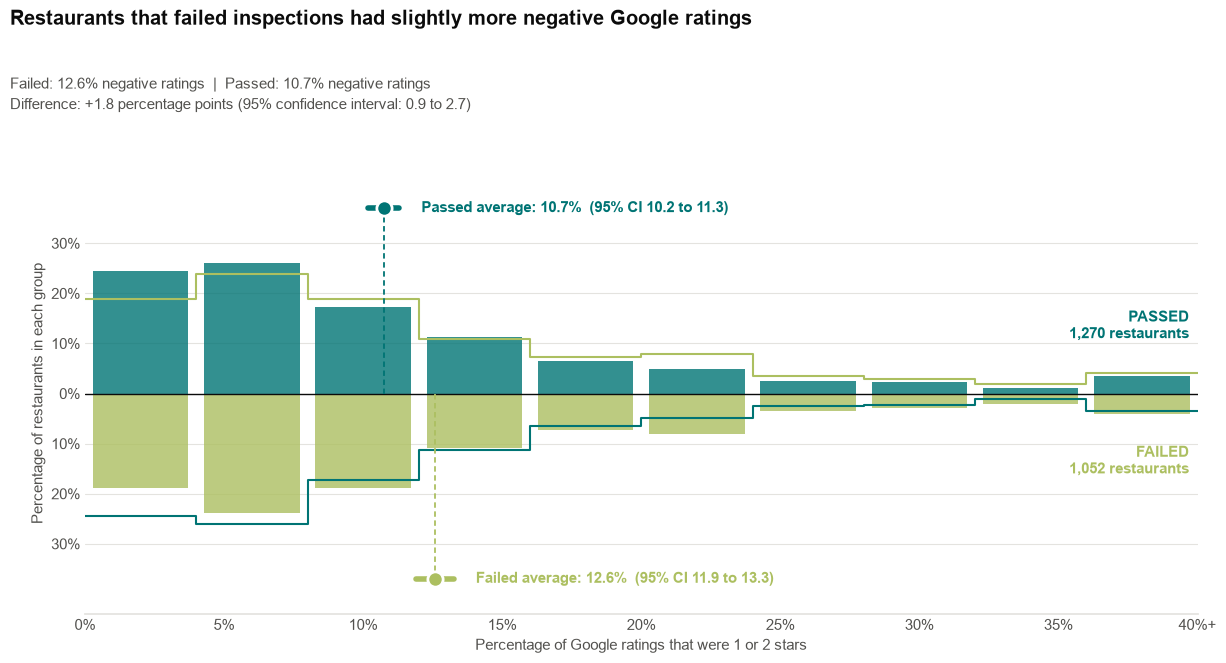

In [127]:

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PASS, FAIL, BAR = "#007474", "#acbf60", "#b9b8b2"

gap, low, high = main["gap"], main["ci_low"], main["ci_high"]
gci = group_ci.set_index("results")
def tidy_axis(ax, grid_axis):
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.grid(axis="y" if grid_axis == "x" else "x", visible=False)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_2, length=0)

pass_vals = inspection_events.loc[inspection_events["results"] == "Pass", "negative_review_percentage"].to_numpy()
fail_vals = inspection_events.loc[inspection_events["results"] == "Fail", "negative_review_percentage"].to_numpy()
CAP, STEP = 40, 4
bins = np.arange(0, CAP + STEP, STEP)
pass_pct = np.histogram(np.clip(pass_vals, 0, CAP - 1e-9), bins=bins)[0] / len(pass_vals) * 100
fail_pct = np.histogram(np.clip(fail_vals, 0, CAP - 1e-9), bins=bins)[0] / len(fail_vals) * 100
centres = bins[:-1] + STEP / 2
if low > 0:
    title = "Restaurants that failed inspections had slightly more negative Google ratings"
elif high < 0:
    title = "Restaurants that failed inspections had fewer negative Google ratings"
else:
    title = "Negative Google ratings were similar for restaurants that passed and failed"

subtitle = (
    f"Failed: {gci.loc['Fail', 'mean']:.1f}% negative ratings  |  "
    f"Passed: {gci.loc['Pass', 'mean']:.1f}% negative ratings\n"
    f"Difference: {gap:+.1f} percentage points "
    f"(95% confidence interval: {low:.1f} to {high:.1f})"
)
fig, ax = plt.subplots(figsize=(12.5, 7.6), facecolor="white")
fig.subplots_adjust(top=0.76, bottom=0.18, left=0.08, right=0.97)
ax.bar(centres, pass_pct, width=STEP * 0.86, color=PASS, alpha=0.80, linewidth=0)
ax.bar(centres, -fail_pct, width=STEP * 0.86, color=FAIL, alpha=0.80, linewidth=0)
edges_x = np.repeat(bins, 2)[1:-1]
ax.plot(edges_x, np.repeat(fail_pct, 2), color=FAIL, linewidth=1.5)
ax.plot(edges_x, -np.repeat(pass_pct, 2), color=PASS, linewidth=1.5)
ax.axhline(0, color=INK, linewidth=1)
peak = np.ceil(max(pass_pct.max(), fail_pct.max()) / 10) * 10
y_top = peak + 14
ax.set_ylim(-y_top, y_top)
ax.set_xlim(0, CAP)

for name, word, color, sign in [("Pass", "Passed", PASS, 1), ("Fail", "Failed", FAIL, -1)]:
    m, lo_ci, hi_ci = gci.loc[name, ["mean", "ci_low", "ci_high"]]
    y_est = sign * (peak + 7)
    ax.plot([m, m], [0, y_est], color=color, linewidth=1.3, linestyle=(0, (3, 2)), zorder=3)
    ax.plot([lo_ci, hi_ci], [y_est, y_est], color=color, linewidth=4, solid_capstyle="round", zorder=4)
    ax.plot(m, y_est, "o", color=color, markersize=11, markeredgecolor="white", markeredgewidth=2, zorder=5)
    ax.text(hi_ci + 0.8, y_est, f"{word} average: {m:.1f}%  (95% CI {lo_ci:.1f} to {hi_ci:.1f})",
            va="center", ha="left", fontsize=11, fontweight="bold", color=color)

ax.text(CAP - 0.3, peak * 0.45, f"PASSED\n{len(pass_vals):,} restaurants", ha="right", va="center",
        fontsize=11, color=PASS, fontweight="bold")
ax.text(CAP - 0.3, -peak * 0.45, f"FAILED\n{len(fail_vals):,} restaurants", ha="right", va="center",
        fontsize=11, color=FAIL, fontweight="bold")
ticks = np.arange(0, peak + 0.1, 10)
ax.set_yticks(np.concatenate([-ticks[::-1][:-1], ticks]))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):.0f}%"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%" if v < CAP else f"{CAP:.0f}%+"))
ax.set_xlabel(
    "Percentage of Google ratings that were 1 or 2 stars",
    fontsize=11, color=INK_2
)
ax.set_ylabel(
    "Percentage of restaurants in each group",
    fontsize=11, color=INK_2
)
tidy_axis(ax, "y")

fig.text(0.02, 0.975, title, fontsize=14.5, fontweight="bold", color=INK, ha="left", va="top", wrap=True)
fig.text(0.02, 0.89, subtitle, fontsize=10.5, color=INK_2, ha="left", va="top", linespacing=1.5)
fig.savefig(visualizations_dir / "visualization.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()


Restaurants have different inspection risk levels so just checked whether the difference in negative Google ratings still appears when comparing restaurants within the same risk category

In [ ]:
risk_table = pd.DataFrame([
    compare_groups(subset, f"Within {risk}", n_perm=1000)
    for risk, subset in inspection_events.dropna(
        subset=["risk_level"]
    ).groupby("risk_level")
])
display(risk_table[check_cols].round(3))

,check,n_fail,n_pass,mean_fail,mean_pass,gap,ci_low,ci_high,p_permutation,median_gap,auc
0,Within Risk 1 (High),924,1079,11.542,9.595,1.948,1.064,2.804,0.001,1.310,0.568
1,Within Risk 2 (Medium),128,191,19.975,17.224,2.751,-0.379,6.057,0.086,2.757,0.548
2,Within Risk 3 (Low),0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Analysis/Findings

Restaurants that failed their first inspection had slightly more 1 and 2 star Google ratings in the year before than restaurants that passed: 12.6% compared with 10.7%. Tha is a gap of about 1.8 percentage points (95% CI 0.9 to 2.7). The interval doesn't include zero. It is still small, though: if you pick one failed and one passed restaurant at random, the failed one has more bad ratings only about 56% of the time.

**How to read the visualization.** Every restaurant in the analysis is in the chart. Restaurants that passed are the blue above the line & restaurants that failed are the green below it. The thin outline on each side is the other group's shape copied over, so the two can be compared directly. The two shapes look almost the same: most restaurants in both groups have very few bad ratings and the failed group is shifted only slightly to the right. The dots at the top and bottom mark each group's average and the short line through each dot is its 95% confidence interval

- **Review window and minimum ratings:** with 6 months, 1 year or 2 years of reviews, and minimums of 5, 10 or 20 ratings, the gap stayed between +1.7 and +2.3 points every time

- **Risk level:** among high risk restaurants the gap was +1.9

This doesn't show that bad reviews cause failed inspections. More likely, the same underlying problems (a messy kitchen, etc) show up in both. Star ratings give a small hint about how a restaurant might do in an inspection but I'd say not  good enough to predict which restaurant will fail